# Exploratory data analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("data/cleaned/books_cleaned.csv")
df.head()

,title,category,book_url,image_url,description,image_path
0,Private Paris (Private #10),Fiction,https://books.toscrape.com/catalogue/private-p...,https://books.toscrape.com/media/cache/9d/05/9...,Paris is burning--and only Private's Jack Morg...,images/book_1.jpg
1,"We Love You, Charlie Freeman",Fiction,https://books.toscrape.com/catalogue/we-love-y...,https://books.toscrape.com/media/cache/5f/15/5...,"The Freeman family--Charles, Laurel, and their...",images/book_2.jpg
2,Thirst,Fiction,https://books.toscrape.com/catalogue/thirst_94...,https://books.toscrape.com/media/cache/c4/0a/c...,"On a searing summer Friday, Eddie Chapman has ...",images/book_3.jpg
3,The Murder That Never Was (Forensic Instincts #5),Fiction,https://books.toscrape.com/catalogue/the-murde...,https://books.toscrape.com/media/cache/dc/44/d...,"Given the opportunity, would you assume someon...",images/book_4.jpg
4,Tuesday Nights in 1980,Fiction,https://books.toscrape.com/catalogue/tuesday-n...,https://books.toscrape.com/media/cache/6b/da/6...,"“In one sentence, Ms. Prentiss captures a sens...",images/book_5.jpg


### Books Category Analysis

In [5]:
print(df["category"].value_counts())

category
Nonfiction    109
Fiction        64
Name: count, dtype: int64


In [11]:
print("Percentage of books category:")
print((df["category"].value_counts(normalize=True) * 100).round(1))

Percentage of books category:
category
Nonfiction    63.0
Fiction       37.0
Name: proportion, dtype: float64


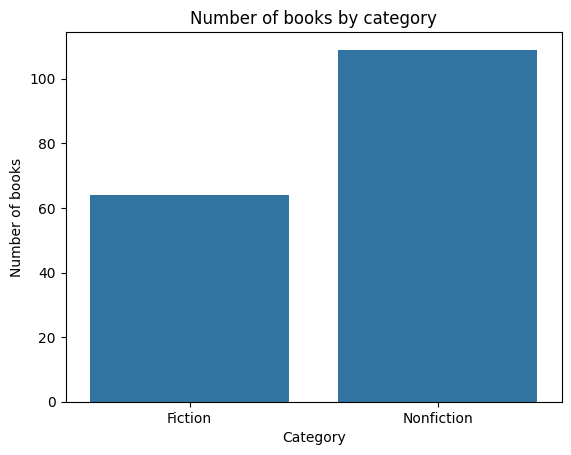

In [12]:
sns.countplot( x="category", data=df, order=["Fiction", "Nonfiction"])
plt.title("Number of books by category")
plt.xlabel("Category")
plt.ylabel("Number of books")
plt.show()

In [21]:
df["title_length"] = df["title"].str.len()
df["description_length"] = df["description"].str.len()

### Books Tittle Analysis


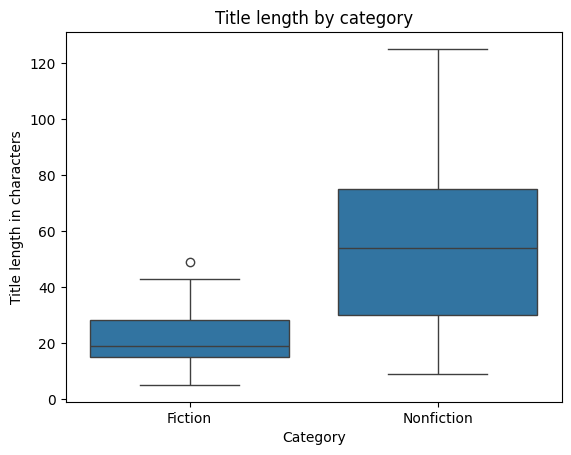

In [ ]:
sns.boxplot(
    x="category",
    y="title_length",
    data=df,
    order=["Fiction", "Nonfiction"]
)

plt.title("Title length by category")
plt.xlabel("Category")
plt.ylabel("Title length in characters")

plt.show()

In [23]:
df.groupby("category")["title_length"].describe()


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Fiction,64.0,21.750000,10.165300,5.0,15.0,19.0,28.25,49.0
Nonfiction,109.0,54.614679,27.690053,9.0,30.0,54.0,75.00,125.0


Text(0, 0.5, 'Density')

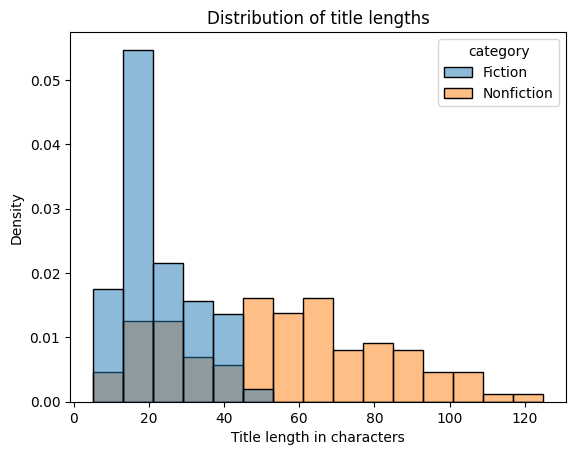

In [36]:

sns.histplot(
    data=df,
    x="title_length",
    hue="category",
    bins=15,
    stat="density",
    common_norm=False
)

plt.title("Distribution of title lengths")
plt.xlabel("Title length in characters")
plt.ylabel("Density")



#### Printing Book with smallest and largest title

In [22]:
df[(df["category"] == "Fiction") & (df["title_length"] > 45)]["title"].iloc[0]

'The Murder That Never Was (Forensic Instincts #5)'

In [33]:
df[(df["category"] == "Nonfiction") & (df["title_length"] >= 125)]["title"].iloc[0]


'10% Happier: How I Tamed the Voice in My Head, Reduced Stress Without Losing My Edge, and Found Self-Help That Actually Works'

In [34]:
df[(df["category"] == "Fiction") & (df["title_length"] <= 5)]["title"].iloc[0]


'Shtum'

In [35]:
df[(df["category"] == "Nonfiction") & (df["title_length"] <=9)]["title"].iloc[0]


'Gratitude'

### Book Description Analysis


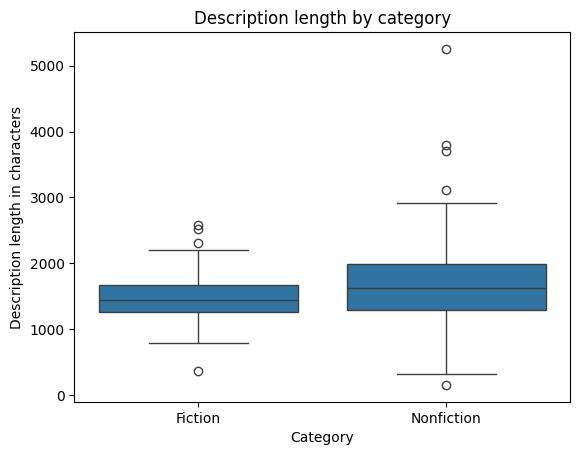

In [37]:
sns.boxplot(
    x="category",
    y="description_length",
    data=df,
    order=["Fiction", "Nonfiction"]
)

plt.title("Description length by category")
plt.xlabel("Category")
plt.ylabel("Description length in characters")

plt.show()

In [38]:
df.groupby("category")["description_length"].describe()

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Fiction,64.0,1470.515625,395.109870,364.0,1260.0,1450.5,1670.75,2584.0
Nonfiction,109.0,1689.403670,681.024176,155.0,1289.0,1622.0,1983.00,5254.0


#### Printing Book with smallest and largest Description


In [40]:
columns = [
    "title",
    "category",
    "description_length",
    "book_url"
]

sorted_books = df.sort_values("description_length")

print("Shortest descriptions:")
display(sorted_books[columns].head(5))

print("Longest descriptions:")
display(sorted_books[columns].tail(5))

Shortest descriptions:


,title,category,description_length,book_url
117,Smarter Faster Better: The Secrets of Being Pr...,Nonfiction,155,https://books.toscrape.com/catalogue/smarter-f...
135,"Data, A Love Story: How I Gamed Online Dating ...",Nonfiction,326,https://books.toscrape.com/catalogue/data-a-lo...
35,The Bourne Identity (Jason Bourne #1),Fiction,364,https://books.toscrape.com/catalogue/the-bourn...
43,Siddhartha,Fiction,785,https://books.toscrape.com/catalogue/siddharth...
146,Stiff: The Curious Lives of Human Cadavers,Nonfiction,800,https://books.toscrape.com/catalogue/stiff-the...


Longest descriptions:


,title,category,description_length,book_url
81,The Genius of Birds,Nonfiction,2918,https://books.toscrape.com/catalogue/the-geniu...
86,Becoming Wise: An Inquiry into the Mystery and...,Nonfiction,3116,https://books.toscrape.com/catalogue/becoming-...
80,The Omnivore's Dilemma: A Natural History of F...,Nonfiction,3707,https://books.toscrape.com/catalogue/the-omniv...
145,The Name of God is Mercy,Nonfiction,3791,https://books.toscrape.com/catalogue/the-name-...
100,Buying In: The Secret Dialogue Between What We...,Nonfiction,5254,https://books.toscrape.com/catalogue/buying-in...


In [41]:
shortest_book = sorted_books.iloc[0]
longest_book = sorted_books.iloc[-1]

print("SHORTEST DESCRIPTION")
print("Title:", shortest_book["title"])
print("URL:", shortest_book["book_url"])
print(shortest_book["description"])

print("LONGEST DESCRIPTION")
print("Title:", longest_book["title"])
print("URL:", longest_book["book_url"])
print(longest_book["description"])

SHORTEST DESCRIPTION
Title: Smarter Faster Better: The Secrets of Being Productive in Life and Business
URL: https://books.toscrape.com/catalogue/smarter-faster-better-the-secrets-of-being-productive-in-life-and-business_543/index.html
A new book that explores the science of productivity, and why, in today’s world, managing how you think—rather than what you think—can transform your life.
LONGEST DESCRIPTION
Title: Buying In: The Secret Dialogue Between What We Buy and Who We Are
URL: https://books.toscrape.com/catalogue/buying-in-the-secret-dialogue-between-what-we-buy-and-who-we-are_670/index.html
“Fascinating … A compelling blend of cultural anthropology and business journalism.” — Andrea Sachs, Time Magazine “An often startling tour of new cultural terrain.” — Laura Miller, Salon “Marked by meticulous research and careful conclusions, this superbly readable book confirms New York Times journalist Walker as an expert on consumerism. … [A] thoughtful and unhurried i “Fascinating … A 

### Book Cover Photo Analysis


In [31]:
from PIL import Image
import numpy as np

In [32]:
widths = []
heights = []
brightness = []

for image_path in df["image_path"]:
    with Image.open(image_path) as image:
        widths.append(image.width)
        heights.append(image.height)

        gray_image = image.convert("L")
        pixels = np.array(gray_image)

        brightness.append(pixels.mean())

df["cover_width"] = widths
df["cover_height"] = heights

df["cover_ratio"] = df["cover_width"] / df["cover_height"]
df["cover_brightness"] = brightness

In [33]:
df.head()

,title,category,book_url,image_url,description,image_path,title_length,description_length,cover_width,cover_height,cover_ratio,cover_brightness
0,Soumission,Fiction,https://books.toscrape.com/catalogue/soumissio...,https://books.toscrape.com/media/cache/3e/ef/3...,"Dans une France assez proche de la nôtre, un h...",images/book_0.jpg,10,1093,101,155,0.651613,225.046247
1,Private Paris (Private #10),Fiction,https://books.toscrape.com/catalogue/private-p...,https://books.toscrape.com/media/cache/9d/05/9...,Paris is burning--and only Private's Jack Morg...,images/book_1.jpg,27,1131,100,155,0.645161,121.468581
2,"We Love You, Charlie Freeman",Fiction,https://books.toscrape.com/catalogue/we-love-y...,https://books.toscrape.com/media/cache/5f/15/5...,"The Freeman family--Charles, Laurel, and their...",images/book_2.jpg,28,1491,102,154,0.662338,85.812198
3,Thirst,Fiction,https://books.toscrape.com/catalogue/thirst_94...,https://books.toscrape.com/media/cache/c4/0a/c...,"On a searing summer Friday, Eddie Chapman has ...",images/book_3.jpg,6,1451,103,155,0.664516,10.144253
4,The Murder That Never Was (Forensic Instincts #5),Fiction,https://books.toscrape.com/catalogue/the-murde...,https://books.toscrape.com/media/cache/dc/44/d...,"Given the opportunity, would you assume someon...",images/book_4.jpg,49,1843,102,155,0.658065,84.952562


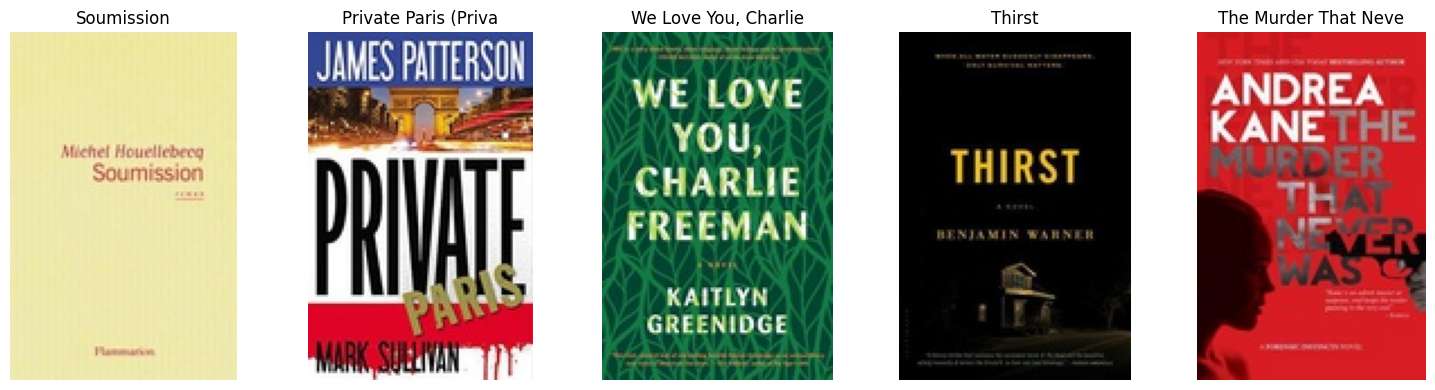

In [37]:
nonfiction = df[df["category"] == "Fiction"]

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i, ax in enumerate(axes):
    img = Image.open(nonfiction["image_path"].iloc[i])
    ax.imshow(img)
    ax.set_title(nonfiction["title"].iloc[i][:20])
    ax.axis("off")

plt.tight_layout()
plt.show()

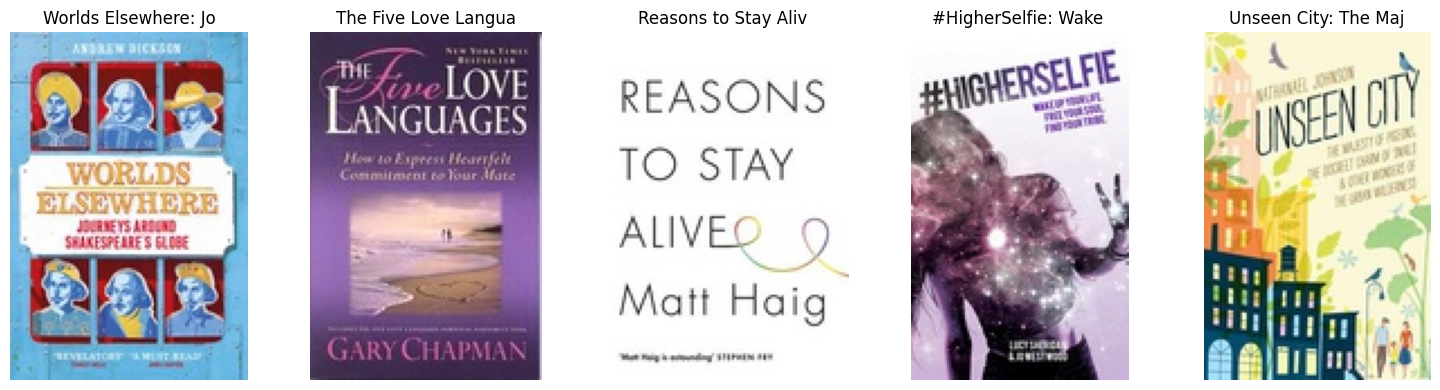

In [36]:
nonfiction = df[df["category"] == "Nonfiction"]

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i, ax in enumerate(axes):
    img = Image.open(nonfiction["image_path"].iloc[i])
    ax.imshow(img)
    ax.set_title(nonfiction["title"].iloc[i][:20])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [38]:
print("Number of different widths and heights:")

print( df[["cover_width", "cover_height"]].nunique())

df.groupby("category")[ ["cover_ratio", "cover_brightness"]].describe()

Number of different widths and heights:
cover_width     30
cover_height     2
dtype: int64


cover_ratio                                                    \
                 count      mean       std       min       25%       50%   
category                                                                   
Fiction           65.0  0.656527  0.020127  0.600000  0.651613  0.658065   
Nonfiction       110.0  0.678439  0.062497  0.564935  0.655844  0.662338   

                               cover_brightness                         \
                 75%       max            count        mean        std   
category                                                                 
Fiction     0.664516  0.709677             65.0  136.564953  54.129725   
Nonfiction  0.670968  1.096774            110.0  147.796974  60.725227   

                                                                      
                  min        25%         50%         75%         max  
category                                                              
Fiction     10.144253  91.463430  145.719014  181.253288  245.565015  
Nonfiction  20.381784  99.935863  151.376194  192.603531  246.476344

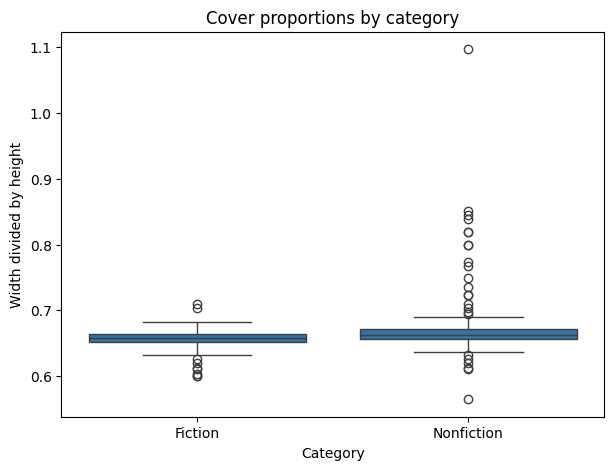

In [39]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    x="category",
    y="cover_ratio",
    data=df,
    order=["Fiction", "Nonfiction"]
)

plt.title("Cover proportions by category")
plt.xlabel("Category")
plt.ylabel("Width divided by height")

plt.show()

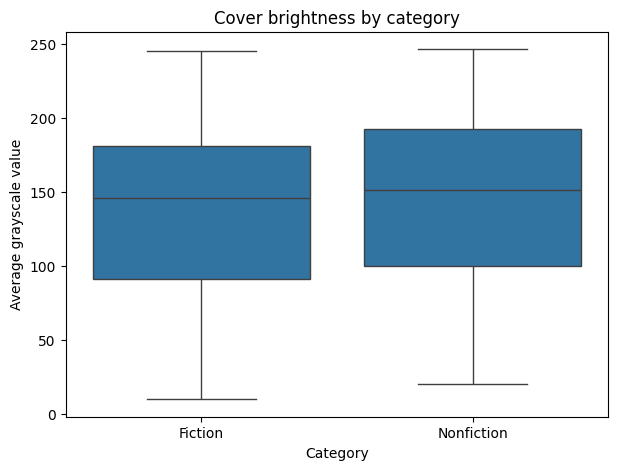

In [40]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    x="category",
    y="cover_brightness",
    data=df,
    order=["Fiction", "Nonfiction"]
)

plt.title("Cover brightness by category")
plt.xlabel("Category")
plt.ylabel("Average grayscale value")

plt.show()

In [42]:
example_rows = [
    df["cover_ratio"].idxmin(),
    df["cover_ratio"].idxmax(),
    df["cover_brightness"].idxmin(),
    df["cover_brightness"].idxmax()
]

labels = ["Narrowest", "Widest", "Darkest", "Brightest"]

df.loc[
    example_rows,
    ["title", "category", "cover_ratio", "cover_brightness"]
]


,title,category,cover_ratio,cover_brightness
120,Man's Search for Meaning,Nonfiction,0.564935,25.364980
94,Swell: A Year of Waves,Nonfiction,1.096774,172.469412
3,Thirst,Fiction,0.664516,10.144253
101,Buying In: The Secret Dialogue Between What We...,Nonfiction,0.658065,246.476344


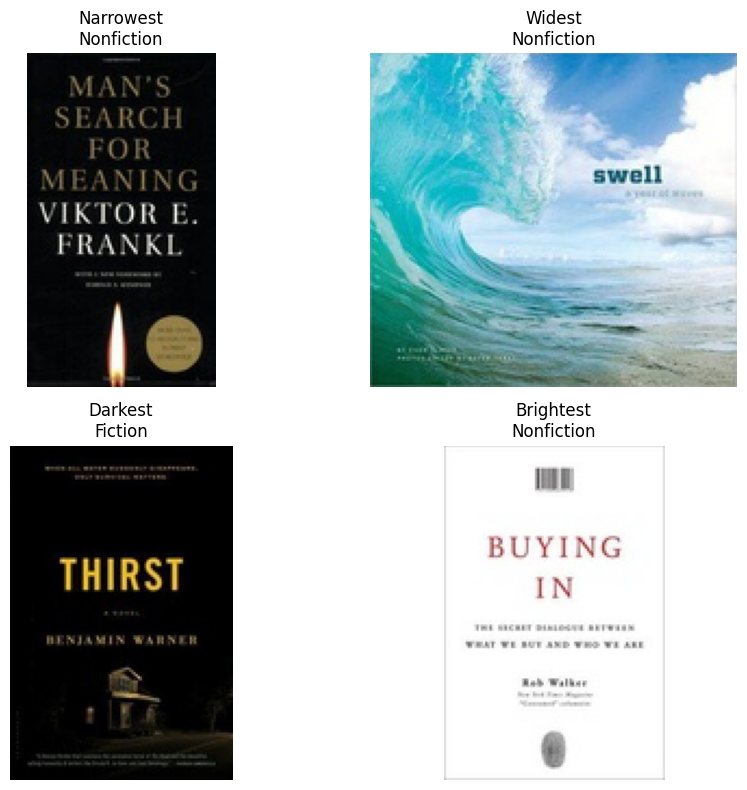

In [43]:
plt.figure(figsize=(10, 8))

for position in range(4):
    book = df.loc[example_rows[position]]

    plt.subplot(2, 2, position + 1)

    with Image.open(book["image_path"]) as image:
        plt.imshow(image)

    plt.title(labels[position] + "\n" + book["category"])
    plt.axis("off")

plt.tight_layout()
plt.show()